# 07 · Análisis del monitoreo, reentrenamiento, ética y resultado de negocio

Responde las secciones 6, 7.4, 8 y 9 del PSet 4 con lo que dejaron en Snowflake los flujos `monitoreo.yml` y `reentrenamiento.yml` (tablas `PRODUCCION.MONITOREO`, `ALERTAS` y `REENTRENAMIENTOS`).

**Convención.** La semana *k* monitorea el lote *k*: sistema, decisiones, datos y deriva. En la misma semana llega el target del lote *k-1*, así que el desempeño y la métrica de negocio se reportan por **lote evaluado**. La deriva inducida empieza en el lote 06 (ver la notebook 06).

In [1]:
from pathlib import Path
import json
import os
import re
import sys

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv
from mlflow.tracking import MlflowClient

load_dotenv(PROJECT_ROOT / ".env")
from monitoreo.alertas import PLANTILLA
from src import almacen
from src.experiments import EXPERIMENT_NAME, configure_tracking
from src.pipeline import model_inputs
from src.reentrenar import MODEL_NAME
from src.simulacion import DERIVA_DESDE_LOTE

API = os.getenv("API_URL_LOCAL", "http://localhost:8000")
AZUL, NARANJA, GRIS, ROJO = "#2a78d6", "#eb6834", "#8a8984", "#d03b3b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8})
pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 70)
configure_tracking()
client = MlflowClient()
q = almacen.consultar
ref = json.loads(Path("monitoreo/referencia.json").read_text(encoding="utf-8"))
U = ref["umbrales"]
mon = q("SELECT * FROM MONITOREO")
alertas = q("SELECT * FROM ALERTAS ORDER BY LOTE, ALERTA")
reent = q("SELECT * FROM REENTRENAMIENTOS ORDER BY LOTE")
SEMANAS_REENT = reent["lote"].astype(int).tolist()

def tabla(tipo=None, metricas=None, eje="lote"):
    m = mon if tipo is None else mon[mon.tipo == tipo]
    if metricas is not None:
        m = m[m.metrica.isin(metricas)]
    m = m[m.feature.isna()]
    return m.pivot_table(index=eje, columns="metrica", values="valor").sort_index()

def marcar_reentrenamientos(ax, desplazar=0):
    for s in SEMANAS_REENT:
        ax.axvline(s + desplazar, color=GRIS, ls="--", lw=1.2)
    ax.axvspan(DERIVA_DESDE_LOTE - 0.5, 11.5, color=NARANJA, alpha=0.07)

print(f"MONITOREO: {len(mon)} filas · ALERTAS: {len(alertas)} · reentrenamientos en las semanas {SEMANAS_REENT}")

MONITOREO: 620 filas · ALERTAS: 21 · reentrenamientos en las semanas [8, 10]


## 1. Métricas de sistema, de modelo y de datos (§6.1)

metrica,solicitudes,predicciones,latencia_p50_ms,latencia_p95_ms,tasa_4xx,tasa_5xx
lote,,,,,,
1,83.0,3096.0,26.435,32.803,0.145,0.0
2,75.0,3537.0,25.514,30.557,0.000,0.0
3,75.0,3524.0,27.275,35.969,0.000,0.0
4,101.0,4718.0,27.023,33.165,0.000,0.0
5,71.0,3434.0,29.058,38.208,0.000,0.0
6,131.0,6509.0,28.858,35.801,0.000,0.0
7,76.0,3551.0,27.790,39.854,0.000,0.0
8,52.0,2253.0,32.115,54.534,0.000,0.0
9,27.0,1324.0,31.213,37.482,0.000,0.0


metrica,prediccion_p10,prediccion_p50,prediccion_p90,tasa_aprobar,tasa_revisar,tasa_respaldo
lote,,,,,,
1,2.025,5.869,13.059,0.0,1.0,0.0
2,2.195,5.095,7.660,0.0,1.0,0.0
3,1.298,3.998,6.018,0.0,1.0,0.0
4,2.188,7.203,11.622,0.0,1.0,0.0
5,1.128,2.755,5.361,0.0,1.0,0.0
6,1.390,2.928,4.250,0.0,1.0,0.0
7,1.098,2.386,11.781,0.0,1.0,0.0
8,3.141,9.018,20.017,0.0,1.0,0.0
9,2.186,7.078,11.707,0.0,1.0,0.0


,fraccion_fuera_de_dominio,categoria_no_vista:fase_movil,categoria_no_vista:tipo_columna,faltantes:columna_diametro_mm,faltantes:columna_longitud_mm,faltantes:columna_particula_um,faltantes:flujo_ml_min,faltantes:gradiente,faltantes:ph_a,faltantes:ph_b,faltantes:t0_min
lote,,,,,,,,,,,
1,0.000,0.124,0.668,0.00,0.00,0.00,0.0,0.0,0.000,0.332,0.000
2,0.000,0.000,1.000,0.00,0.00,0.00,0.0,0.0,0.000,0.000,0.000
3,0.000,0.000,1.000,0.00,0.00,0.00,0.0,0.0,0.000,0.000,0.000
4,0.003,0.843,0.991,0.00,0.00,0.00,0.0,0.0,0.003,0.009,0.000
5,0.000,0.024,0.072,0.00,0.00,0.00,0.0,0.0,0.000,0.856,0.000
6,0.000,0.000,0.000,0.00,0.00,0.00,0.0,0.0,0.000,1.000,0.000
7,0.014,0.041,0.337,0.00,0.00,0.00,0.0,0.0,1.000,1.000,0.000
8,0.106,0.134,0.333,0.02,0.02,0.02,0.0,0.0,1.000,1.000,0.073
9,0.000,1.000,1.000,0.00,0.00,0.00,1.0,0.0,1.000,1.000,1.000


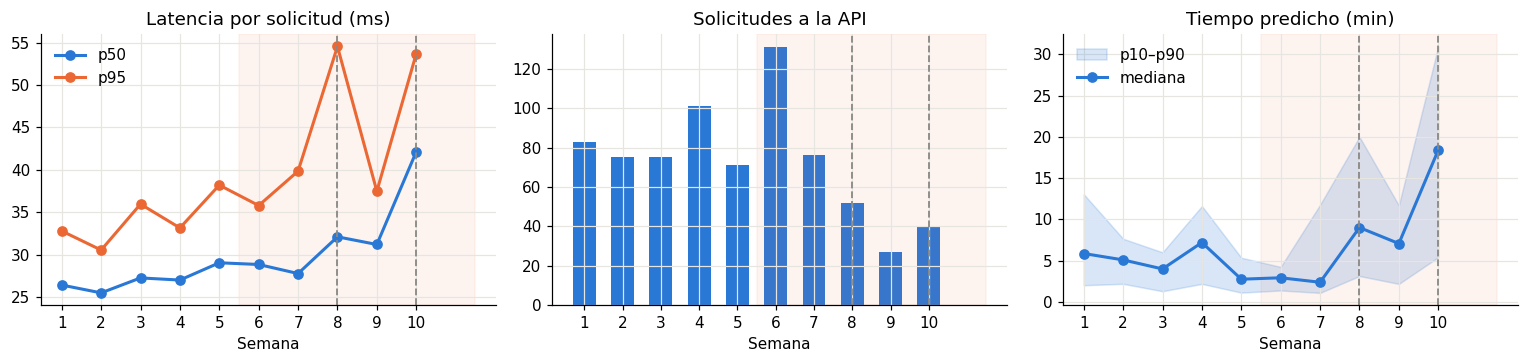

Latencia p95 máxima: 55 ms (umbral 500 ms). 5xx: 0%. Decisión 'aprobar': 0% en todas las semanas.


In [2]:
sistema = tabla("sistema")[["solicitudes", "predicciones", "latencia_p50_ms", "latencia_p95_ms", "tasa_4xx", "tasa_5xx"]]
modelo = tabla("modelo")[["prediccion_p10", "prediccion_p50", "prediccion_p90", "tasa_aprobar", "tasa_revisar", "tasa_respaldo"]]
datos = tabla("datos")[["fraccion_fuera_de_dominio"]].join(
    mon[mon.metrica.isin(["categoria_no_vista", "faltantes"])].assign(col=lambda d: d.metrica + ":" + d.feature)
    .pivot_table(index="lote", columns="col", values="valor"))
display(sistema.round(3)); display(modelo.round(3)); display(datos.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].plot(sistema.index, sistema.latencia_p50_ms, color=AZUL, marker="o", lw=2, label="p50")
axes[0].plot(sistema.index, sistema.latencia_p95_ms, color=NARANJA, marker="o", lw=2, label="p95")
axes[0].set(title="Latencia por solicitud (ms)", xlabel="Semana"); axes[0].legend(frameon=False)
axes[1].bar(sistema.index, sistema.solicitudes, color=AZUL, width=0.6)
axes[1].set(title="Solicitudes a la API", xlabel="Semana")
axes[2].fill_between(modelo.index, modelo.prediccion_p10, modelo.prediccion_p90, color=AZUL, alpha=0.18, label="p10–p90")
axes[2].plot(modelo.index, modelo.prediccion_p50, color=AZUL, marker="o", lw=2, label="mediana")
axes[2].set(title="Tiempo predicho (min)", xlabel="Semana"); axes[2].legend(frameon=False)
for ax in axes:
    marcar_reentrenamientos(ax); ax.set_xticks(range(1, 11))
plt.tight_layout(); plt.show()
print(f"Latencia p95 máxima: {sistema.latencia_p95_ms.max():.0f} ms (umbral {U['latencia_p95_ms']:.0f} ms). 5xx: {sistema.tasa_5xx.max():.0%}. "
      f"Decisión 'aprobar': {modelo.tasa_aprobar.max():.0%} en todas las semanas.")

**Lectura.** El servicio no es el cuello de botella: p95 por debajo de 60 ms y ningún 5xx. Los únicos 4xx están en la semana 1 (12 solicitudes, sección 3). La mediana predicha sube desde el lote 08 porque llegan métodos más largos. El modelo nunca aprueba: con el intervalo del PSet 3 (±8 min por par) ningún par de picos predicho queda separado con certeza.

## 2. Deriva de datos y deriva conceptual (§6.2)

### 2.1 Por qué los umbrales de PSI no son 0,1 y 0,25

Cada lote reúne pocos laboratorios, y cada laboratorio trae su propia librería de compuestos. Con el umbral clásico (PSI > 0,25), los lotes **sin alterar** alertarían todas las semanas. Por eso el umbral de cada descriptor se calibra con 200 *pseudo-lotes*: grupos de experimentos del propio entrenamiento de unas 3 000 filas. Esos pseudo-lotes son lotes normales de la misma población, y el umbral es el percentil 99 de su PSI. Para alertar se exigen **al menos 2 descriptores** sobre su umbral, y la prueba KS (p < 0,01) queda como respaldo.

In [3]:
psi = mon[mon.metrica == "psi"].pivot_table(index="feature", columns="lote", values="valor")
cal = pd.DataFrame({"umbral_calibrado_p99": U["psi"], "mediana_pseudo_lotes": ref["pseudo_lotes"]["psi_p50"]})
cal["lotes_sin_alterar_con_psi>0.25"] = (psi.loc[:, psi.columns < DERIVA_DESDE_LOTE] > 0.25).sum(axis=1)
cal["lotes_sin_alterar_sobre_umbral_calibrado"] = psi.loc[:, psi.columns < DERIVA_DESDE_LOTE].gt(pd.Series(U["psi"]), axis=0).sum(axis=1)
display(cal.round(3))
print("Con PSI > 0,25 alertarían", int((psi.loc[:, psi.columns < DERIVA_DESDE_LOTE] > 0.25).any().sum()), "de 5 lotes sin alterar;",
      "con el umbral calibrado y la regla de 2 descriptores, 1 de 5 (lote 05, sección 3).")

,umbral_calibrado_p99,mediana_pseudo_lotes,lotes_sin_alterar_con_psi>0.25,lotes_sin_alterar_sobre_umbral_calibrado
mol_weight,1.524,0.982,5,0
mol_logp,1.477,0.718,4,0
mol_tpsa,0.549,0.339,5,2
mol_h_donors,0.975,0.478,1,1
mol_h_acceptors,0.679,0.482,5,0
mol_rotatable_bonds,0.544,0.393,3,0
mol_ring_count,1.737,1.258,5,0
mol_aromatic_rings,1.834,1.197,5,0
mol_fraction_csp3,0.679,0.445,4,0


Con PSI > 0,25 alertarían 5 de 5 lotes sin alterar; con el umbral calibrado y la regla de 2 descriptores, 1 de 5 (lote 05, sección 3).


,descriptores_psi_sobre_umbral,de_ellos_confirmados_por_ks,alerta_deriva_datos,chi2_p_columna,chi2_p_fase_movil
lote,,,,,
1,0,0,False,0.0,0.0
2,0,0,False,0.0,0.0
3,0,0,False,0.0,0.0
4,1,1,False,0.0,0.0
5,2,2,True,0.0,0.0
6,0,0,False,0.0,0.0
7,1,1,False,0.0,0.0
8,1,1,False,0.0,0.0
9,1,1,False,0.0,0.0


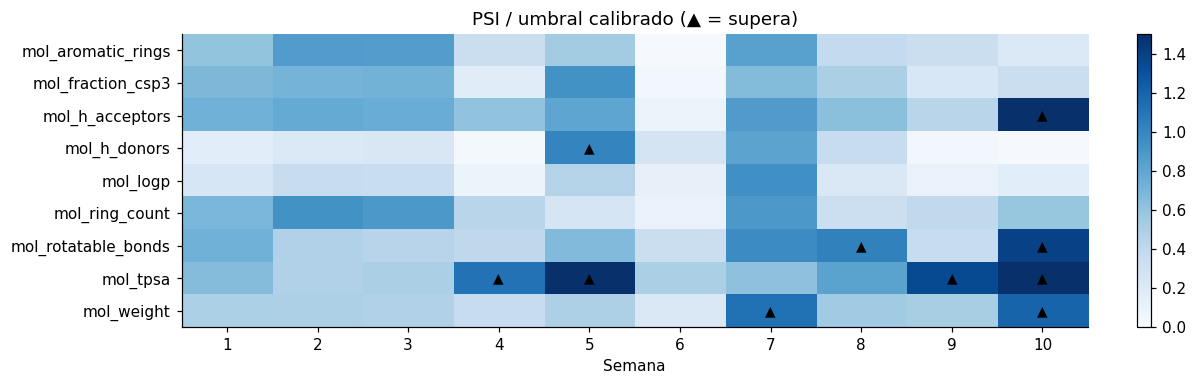

In [4]:
ks = mon[mon.metrica == "ks_p"].pivot_table(index="feature", columns="lote", values="valor")
chi = mon[mon.metrica == "chi2_p"].pivot_table(index="feature", columns="lote", values="valor")
sobre = psi.gt(pd.Series(U["psi"]), axis=0)
resumen_deriva = pd.DataFrame({
    "descriptores_psi_sobre_umbral": sobre.sum(),
    "de_ellos_confirmados_por_ks": (sobre & (ks < U["ks_p_valor"])).sum(),
    "alerta_deriva_datos": sobre.sum() >= U["psi_features_para_alerta"],
    "chi2_p_columna": chi.loc["tipo_columna"], "chi2_p_fase_movil": chi.loc["fase_movil"],
})
display(resumen_deriva.round(4))

fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow((psi.div(pd.Series(U["psi"]), axis=0)).clip(upper=1.5), cmap="Blues", vmin=0, vmax=1.5, aspect="auto")
for (i, f) in enumerate(psi.index):
    for (j, l) in enumerate(psi.columns):
        if sobre.loc[f, l]:
            ax.text(j, i, "▲", ha="center", va="center", fontsize=9)
ax.set(xticks=range(len(psi.columns)), xticklabels=psi.columns, yticks=range(len(psi.index)), yticklabels=psi.index,
       xlabel="Semana", title="PSI / umbral calibrado (▲ = supera)")
ax.grid(False); fig.colorbar(im, ax=ax, fraction=0.025); plt.tight_layout(); plt.show()

**Las pruebas estadísticas no sirven como alarma aquí.** Con miles de filas por lote, KS y chi-cuadrado rechazan casi siempre (p ≈ 0), incluso en lotes normales, porque cada lote es otra librería de compuestos y otra columna. Por eso deciden el PSI calibrado y la regla de 2 descriptores, y la prueba estadística solo confirma (columna `de_ellos_confirmados_por_ks`).

### 2.2 Deriva conceptual

El PSet pide comparar la métrica técnica de cada lote con la media y la desviación estándar de la CV del PSet 3. Esa desviación (0,035 min) mide la variación entre pliegues **por compuesto** dentro de los mismos laboratorios, no entre laboratorios nuevos. Por eso todos los lotes quedan a decenas de desviaciones (`z_vs_cv`), sin alteración y en ambas direcciones. La comparación se reporta, pero la alerta usa el percentil 95 del RMSE y del sesgo de los pseudo-lotes fuera de pliegue (OOF). Así se pregunta "¿este lote es peor que un grupo normal de laboratorios no vistos?".

,alerta_desempeno,mae,orden_exactitud_2min,rmse,rmse_linea_base,sesgo,sesgo_abs,z_vs_cv,diagnostico,cv_media,cv_de
lote_evaluado,,,,,,,,,,,
1.0,0.0,1.406,0.986,1.680,8.030,0.877,0.877,-19.067,estable,2.343,0.035
2.0,0.0,1.122,0.989,1.364,8.416,0.957,0.957,-28.164,estable,2.343,0.035
3.0,0.0,0.579,0.995,0.738,8.434,-0.119,0.119,-46.160,estable,2.343,0.035
4.0,0.0,1.470,0.934,1.964,5.897,-0.203,0.203,-10.914,estable,2.343,0.035
5.0,0.0,0.989,0.951,1.434,3.036,-0.196,0.196,-26.139,deriva de datos sin impacto,2.343,0.035
6.0,1.0,1.917,0.879,2.175,2.388,-1.884,1.884,-4.838,deriva conceptual,2.343,0.035
7.0,1.0,3.821,0.865,5.340,7.185,-3.202,3.202,86.177,deriva conceptual,2.343,0.035
8.0,1.0,4.030,0.855,5.073,6.431,-1.196,1.196,78.514,deriva conceptual,2.343,0.035
9.0,1.0,2.922,0.900,3.427,3.920,-2.773,2.773,31.159,deriva conceptual,2.343,0.035


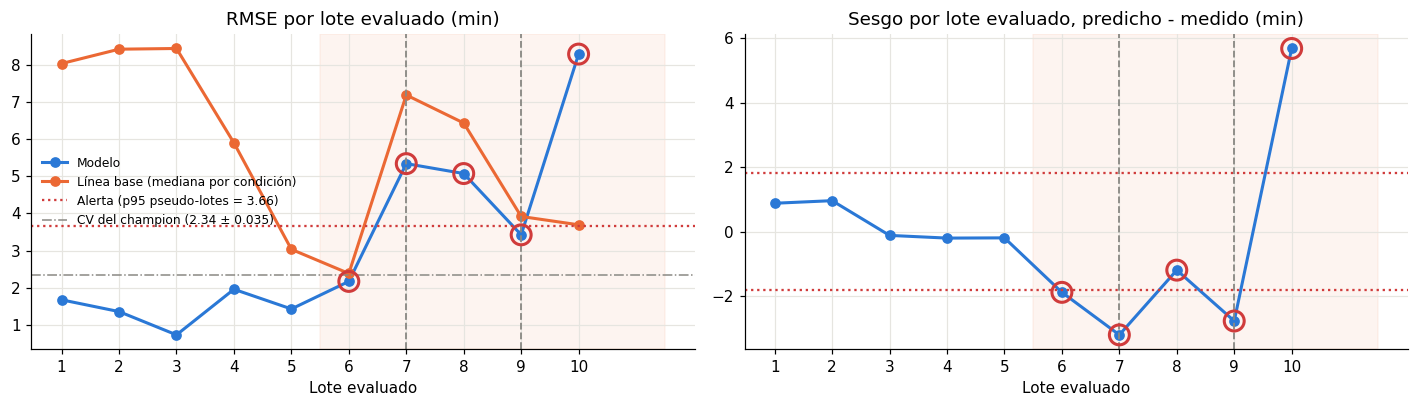

Líneas grises: reentrenamientos (semanas 8 y 10 = después de evaluar los lotes 7 y 9). Círculos: lotes con alerta de desempeño.


In [5]:
des = tabla(metricas=["rmse", "sesgo", "sesgo_abs", "z_vs_cv", "rmse_linea_base", "mae", "orden_exactitud_2min", "alerta_desempeno"], eje="lote_evaluado")
diag = mon[mon.metrica.str.startswith("diagnostico:", na=False)].assign(diagnostico=lambda d: d.metrica.str.removeprefix("diagnostico:"))
des = des.join(diag.set_index("lote_evaluado")["diagnostico"])
des["cv_media"], des["cv_de"] = ref["cv"]["rmse_media"], ref["cv"]["rmse_de"]
display(des.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(des.index, des.rmse, color=AZUL, marker="o", lw=2, label="Modelo")
axes[0].plot(des.index, des.rmse_linea_base, color=NARANJA, marker="o", lw=2, label="Línea base (mediana por condición)")
axes[0].axhline(U["rmse_lote"], color=ROJO, ls=":", label=f"Alerta (p95 pseudo-lotes = {U['rmse_lote']:.2f})")
axes[0].axhline(ref["cv"]["rmse_media"], color=GRIS, ls="-.", lw=1, label=f"CV del champion ({ref['cv']['rmse_media']:.2f} ± {ref['cv']['rmse_de']:.3f})")
axes[0].set(title="RMSE por lote evaluado (min)", xlabel="Lote evaluado")
axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(des.index, des.sesgo, color=AZUL, marker="o", lw=2)
for s in (1, -1):
    axes[1].axhline(s * U["sesgo_abs_lote"], color=ROJO, ls=":")
axes[1].set(title="Sesgo por lote evaluado, predicho - medido (min)", xlabel="Lote evaluado")
for ax in axes:
    marcar_reentrenamientos(ax, desplazar=-1); ax.set_xticks(range(1, 11))
    alertados = des[des.alerta_desempeno == 1]
    ax.scatter(alertados.index, alertados.rmse if ax is axes[0] else alertados.sesgo, s=170, facecolors="none", edgecolors=ROJO, lw=2, zorder=5)
plt.tight_layout(); plt.show()
print("Líneas grises: reentrenamientos (semanas 8 y 10 = después de evaluar los lotes 7 y 9). Círculos: lotes con alerta de desempeño.")

### 2.3 Diagnóstico y acción

| Entradas | Desempeño | Diagnóstico | Acción en QSRR-Predict | Lotes donde ocurrió |
|---|---|---|---|---|
| Cambian | Se mantiene | Deriva de datos sin impacto | Registrar la alerta (severidad media) y avisar al equipo de datos. **No se reentrena.** Si la causa es un catálogo nuevo de columnas o fases, ampliarlo. | 05 (PSI en 2 descriptores, RMSE 1,43) |
| Cambian | Cae | Deriva de datos con impacto | Forzar "revisar" en los métodos fuera de dominio (la guardia ya lo hace). Con 2 lotes seguidos, reentrenar incluyendo esos métodos; si el reentrenamiento no basta, criterio de retirada R2. | 10 (100 % fuera de dominio, RMSE 8,3) |
| Estables | Cae | Deriva conceptual | Avisar al laboratorio: revisar el equipo y el método (volumen de retardo, temperatura, columna gastada). Con 2 lotes seguidos, reentrenar con los lotes recientes con mayor peso. | 06–09 (la deriva inducida; el 08 suma degradación natural) |

El diagnóstico de cada lote lo calcula `monitoreo/alertas.py`, cruzando la alerta de desempeño del lote con su alerta de entradas (PSI o fuera de dominio). Para el lote 10 sale "con impacto", como se esperaba.

## 3. Alertas (§6.3)

### 3.1 Plantilla

In [6]:
plantilla = pd.DataFrame([
    {"alerta": k, "metrica": m, "umbral": u, "ventana": v[0], "severidad": v[1], "quien_la_recibe": v[2], "accion": v[3]}
    for k, (m, u), v in [
        ("desempeno_rmse", ("RMSE del lote evaluado", f"> {U['rmse_lote']:.2f} min (p95 pseudo-lotes)"), PLANTILLA["desempeno_rmse"]),
        ("desempeno_sesgo", ("|error medio| del lote", f"> {U['sesgo_abs_lote']:.2f} min (p95 pseudo-lotes)"), PLANTILLA["desempeno_sesgo"]),
        ("deriva_datos", ("descriptores con PSI > p99 calibrado", f">= {U['psi_features_para_alerta']} (KS p < {U['ks_p_valor']} como respaldo)"), PLANTILLA["deriva_datos"]),
        ("fuera_de_dominio", ("fracción de analitos fuera del rango de entrenamiento", f"> {U['fraccion_fuera_de_dominio']:.0%}"), PLANTILLA["fuera_de_dominio"]),
        ("categoria_no_vista", ("fracción con columna o fase no vista", f"> {U['fraccion_categoria_no_vista']:.0%}"), PLANTILLA["categoria_no_vista"]),
        ("latencia_p95", ("latencia p95", f"> {U['latencia_p95_ms']:.0f} ms"), PLANTILLA["latencia_p95"]),
        ("errores_4xx", ("tasa 4xx", f"> {U['tasa_4xx']:.0%}"), PLANTILLA["errores_4xx"]),
        ("errores_5xx", ("tasa 5xx", f"> {U['tasa_5xx']:.0%}"), PLANTILLA["errores_5xx"]),
        ("reentrenamiento", ("alerta de desempeño", f"{U['lotes_consecutivos_reentrenamiento']} lotes evaluados seguidos, o cada {U['reentrenamiento_calendario_lotes']} lotes"), PLANTILLA["reentrenamiento"]),
    ]])
display(plantilla)

,alerta,metrica,umbral,ventana,severidad,quien_la_recibe,accion
0,desempeno_rmse,RMSE del lote evaluado,> 3.66 min (p95 pseudo-lotes),1 lote,Alta,Ciencia de datos,Diagnosticar; con 2 lotes seguidos se reentrena
1,desempeno_sesgo,|error medio| del lote,> 1.81 min (p95 pseudo-lotes),1 lote,Alta,Ciencia de datos + laboratorio,"Revisar equipo y método (volumen de retardo, temperatura); con 2 l..."
2,deriva_datos,descriptores con PSI > p99 calibrado,>= 2 (KS p < 0.01 como respaldo),1 lote,Media,Equipo de datos,Revisar la fuente; no reentrenar si el desempeño se mantiene
3,fuera_de_dominio,fracción de analitos fuera del rango de entrenamiento,> 20%,1 lote,Alta,Analistas + ciencia de datos,Confirmar con corrida exploratoria; incorporar esos métodos al ree...
4,categoria_no_vista,fracción con columna o fase no vista,> 50%,1 lote,Baja,Equipo de datos,Informativa: ampliar el catálogo de columnas y fases
5,latencia_p95,latencia p95,> 500 ms,1 lote,Media,Plataforma,Escalar el servicio
6,errores_4xx,tasa 4xx,> 5%,1 lote,Media,Equipo de datos,Revisar la calidad de las solicitudes
7,errores_5xx,tasa 5xx,> 1%,1 lote,Alta,Plataforma,Revisar el servicio o activar el respaldo
8,reentrenamiento,alerta de desempeño,"2 lotes evaluados seguidos, o cada 8 lotes",2 lotes consecutivos,Alta,Ciencia de datos,Lanzar reentrenamiento.yml (challenger + aprobación humana)


### 3.2 Alertas disparadas y falsas alarmas

Una alerta en un lote sin alterar (semanas 1–5, o el desempeño de los lotes 1–5) es una falsa alarma respecto de la deriva inducida. Cada una se clasifica con su causa y el ajuste propuesto.

In [7]:
a = alertas[["lote", "lote_evaluado", "alerta", "severidad", "metrica", "valor", "umbral", "diagnostico"]].copy()
lote_ref = a.lote_evaluado.fillna(a.lote).astype(int)
a["lote_alterado"] = lote_ref >= DERIVA_DESDE_LOTE
CAUSAS = {
    ("errores_4xx", False): ("Falsa alarma de deriva, pero alarma real de calidad: 12 solicitudes con b_meoh = 'NA' en RepoRT; la API las rechaza (422) como debe.",
                             "Mantener el umbral; limpiar 'NA' en Silver (dbt) para que no lleguen a producción."),
    ("categoria_no_vista", False): ("Esperada: cada laboratorio nuevo trae su propia columna o fase; no afecta al modelo, que usa descriptores numéricos.",
                                    "Bajarla a informativa (ya es severidad baja) o alertar solo si coincide con caída de desempeño."),
    ("deriva_datos", False): ("Falsa alarma en el límite: 2 descriptores (mol_tpsa, mol_h_donors) justo sobre p99; el desempeño del lote 05 es bueno (RMSE 1,43).",
                              "Exigir 3 descriptores o p99,5; con 3, el lote 05 no alerta y el lote 10 (4 descriptores) sigue alertando."),
}
a["causa"], a["ajuste"] = zip(*[CAUSAS.get((r.alerta, r.lote_alterado), ("Esperada: lote con deriva o fuera de dominio.", "—")) for r in a.itertuples()])
display(a)
falsas = a[~a.lote_alterado]
print(f"{len(a)} alertas: {int(a.lote_alterado.sum())} en lotes alterados y {len(falsas)} en lotes sin alterar "
      f"({falsas.alerta.value_counts().to_dict()}). Ninguna alerta de desempeño ni de reentrenamiento cayó en un lote sin alterar.")
assert not falsas.alerta.isin(["desempeno_rmse", "desempeno_sesgo", "reentrenamiento"]).any()

,lote,lote_evaluado,alerta,severidad,metrica,valor,umbral,diagnostico,lote_alterado,causa,ajuste
0,1,NaN,categoria_no_vista,Baja,categoria_no_vista:tipo_columna,0.668269,0.500000,None,False,Esperada: cada laboratorio nuevo trae su propia columna o fase; no...,Bajarla a informativa (ya es severidad baja) o alertar solo si coi...
1,1,NaN,errores_4xx,Media,tasa_4xx,0.144578,0.050000,None,False,"Falsa alarma de deriva, pero alarma real de calidad: 12 solicitude...",Mantener el umbral; limpiar 'NA' en Silver (dbt) para que no llegu...
2,2,NaN,categoria_no_vista,Baja,categoria_no_vista:tipo_columna,1.000000,0.500000,None,False,Esperada: cada laboratorio nuevo trae su propia columna o fase; no...,Bajarla a informativa (ya es severidad baja) o alertar solo si coi...
3,3,NaN,categoria_no_vista,Baja,categoria_no_vista:tipo_columna,1.000000,0.500000,None,False,Esperada: cada laboratorio nuevo trae su propia columna o fase; no...,Bajarla a informativa (ya es severidad baja) o alertar solo si coi...
4,4,NaN,categoria_no_vista,Baja,categoria_no_vista:tipo_columna,0.991310,0.500000,None,False,Esperada: cada laboratorio nuevo trae su propia columna o fase; no...,Bajarla a informativa (ya es severidad baja) o alertar solo si coi...
5,4,NaN,categoria_no_vista,Baja,categoria_no_vista:fase_movil,0.842730,0.500000,None,False,Esperada: cada laboratorio nuevo trae su propia columna o fase; no...,Bajarla a informativa (ya es severidad baja) o alertar solo si coi...
6,5,NaN,deriva_datos,Media,"psi (mol_tpsa, mol_h_donors)",2.000000,2.000000,None,False,"Falsa alarma en el límite: 2 descriptores (mol_tpsa, mol_h_donors)...","Exigir 3 descriptores o p99,5; con 3, el lote 05 no alerta y el lo..."
7,7,6.0,desempeno_sesgo,Alta,sesgo_abs,1.884139,1.813065,deriva conceptual,True,Esperada: lote con deriva o fuera de dominio.,—
8,8,7.0,desempeno_rmse,Alta,rmse,5.339927,3.659454,deriva conceptual,True,Esperada: lote con deriva o fuera de dominio.,—
9,8,7.0,desempeno_sesgo,Alta,sesgo_abs,3.202422,1.813065,deriva conceptual,True,Esperada: lote con deriva o fuera de dominio.,—


21 alertas: 14 en lotes alterados y 7 en lotes sin alterar ({'categoria_no_vista': 5, 'errores_4xx': 1, 'deriva_datos': 1}). Ninguna alerta de desempeño ni de reentrenamiento cayó en un lote sin alterar.


## 4. Ciclo completo sobre la deriva inducida (§7.4)

**Disparador (§7.1).** Se reentrena por desempeño cuando hay alerta de RMSE o de sesgo en **2 lotes evaluados seguidos** con el champion vigente. Con 1 lote bastaría un laboratorio atípico (el lote 08 falla incluso sin la deriva), y con 3 lotes se predecirían 3 semanas con tiempos sesgados. También se reentrena por calendario cada 8 lotes evaluados. La deriva de datos sola no dispara, y solo se usan lotes cuyo target ya llegó.

**Ventana (§7.2).** Todo el histórico (experimentos 0006–0275, peso 1) más los lotes con target (peso 10). Los métodos del laboratorio cambian de verdad, así que lo reciente debe pesar, pero sin olvidar las 103 200 filas que sostienen la química del modelo. Una ventana móvil solo con lotes recientes tendría unas 20 000 filas de pocos laboratorios.

**Secuencia:** alerta en los lotes 06 y 07 → semana 8 → challenger v4 → **rechazado**. Alerta en los lotes 08 y 09 → semana 10 → challenger v5 → **aprobado** → el alias `champion` pasa al v5.

In [8]:
runs = mlflow.search_runs(experiment_names=[EXPERIMENT_NAME], filter_string="tags.fase = 'reentrenamiento'")
cols = ["run_id", "start_time", "status", "tags.motivo", "tags.ventana", "tags.semana_disparo", "tags.regla_promueve",
        "tags.decision_humana", "tags.motivo_decision", "metrics.cv_rmse_mean", "metrics.cv_rmse_std"]
display(runs[[c for c in cols if c in runs]].sort_values("start_time"))
ciclo = reent[["lote", "motivo", "version_champion", "version_challenger", "lote_evaluacion", "rmse_champion", "rmse_challenger",
               "cv_std_champion", "regla_promueve", "decision_humana", "motivo_decision", "version_champion_final"]]
display(ciclo.T)
alias = client.get_registered_model(MODEL_NAME).aliases  # al aprobar, 'challenger' pasa a 'champion'
versiones = pd.DataFrame([{"version": int(v.version), "run_id": v.run_id[:8], "aliases": ",".join(v.aliases) or "—",
                           "fase": client.get_run(v.run_id).data.tags.get("fase")}
                          for v in client.search_model_versions(f"name='{MODEL_NAME}'")]).sort_values("version")
display(versiones)
print("Aliases actuales:", alias, "| /modelo de la API:", requests.get(f"{API}/modelo", timeout=10).json()["version"])

,run_id,start_time,status,tags.motivo,tags.ventana,tags.semana_disparo,tags.regla_promueve,tags.decision_humana,tags.motivo_decision,metrics.cv_rmse_mean,metrics.cv_rmse_std
2,212bd95945ac42ec8e2d8274855c22cc,2026-11-23 03:10:28.783000+00:00,FINISHED,calendario: 6 lotes evaluados desde el último reentrenamiento,"histórico 0006-0275 (peso 1) + lotes [1, 2, 3, 4, 5] (peso 10)",7,True,None,None,2.246655,0.035577
1,b2d323ff382e4562bc10759c7f3f29ff,2026-11-23 03:31:12.397000+00:00,FINISHED,"desempeño: alerta de RMSE o sesgo en 2 lotes consecutivos (6, 7)","histórico 0006-0275 (peso 1) + lotes [1, 2, 3, 4, 5, 6] (peso 10)",8,False,rechazado,"mejora 0,03 < 1 DE de CV; la regla no promueve",2.209782,0.032734
0,372817b3934042e084a061d0dd81047d,2026-11-23 04:01:04.816000+00:00,FINISHED,"desempeño: alerta de RMSE o sesgo en 2 lotes consecutivos (8, 9)","histórico 0006-0275 (peso 1) + lotes [1, 2, 3, 4, 5, 6, 7, 8] (pes...",10,True,aprobado,"La regla promueve: RMSE 3,43 -> 2,86 en el lote 9 (mejora > 1 DE d...",2.244530,0.031081


,0,1
lote,8,10
motivo,"desempeño: alerta de RMSE o sesgo en 2 lotes consecutivos (6, 7)","desempeño: alerta de RMSE o sesgo en 2 lotes consecutivos (8, 9)"
version_champion,2,2
version_challenger,4,5
lote_evaluacion,7,9
rmse_champion,5.339927,3.426741
rmse_challenger,5.310008,2.861893
cv_std_champion,0.034774,0.034774
regla_promueve,False,True
decision_humana,rechazado,aprobado


,version,run_id,aliases,fase
4,1,f6617bca,—,entrenamiento_inicial
3,2,ac566f02,—,entrenamiento_descriptores_metodo
2,3,212bd959,—,reentrenamiento
1,4,b2d323ff,—,reentrenamiento
0,5,372817b3,—,reentrenamiento


Aliases actuales: {'champion': '5'} | /modelo de la API: 5


La corrida `212bd959` (versión 3, sin alias ni decisión) es de una ejecución anterior de la simulación. Se disparó por calendario en la semana 7, cuando el calendario era de 6 lotes y coincidía con el primer lote con deriva. Esa ejecución de Kestra se canceló antes de la pausa de aprobación, se subió el calendario a 8 lotes y la simulación se repitió desde cero. Queda en MLflow por trazabilidad, pero no aparece en `REENTRENAMIENTOS`.

### 4.1 ¿Qué efecto tuvo el reentrenamiento?

En la simulación, el v5 se aprobó después de predecir el último lote, así que nunca sirvió tráfico. Su efecto se mide fuera de línea: cada versión se evalúa en los lotes que **no** vio en su entrenamiento (v2: ninguno; v4: hasta el 06; v5: hasta el 08). El target es el medido, con la deriva.

In [9]:
lab = q("""SELECT e.*, m.TIEMPO_RETENCION FROM LOTES_ENTRADAS e
            JOIN LAB_MEDICIONES m ON e.HECHO_ID = m.HECHO_ID AND e.LOTE = m.LOTE WHERE e.LOTE >= 6""")
X, y, _ = model_inputs(lab)
vio_hasta = {2: 0, 4: 6, 5: 8}
efecto = []
for version, hasta in vio_hasta.items():
    modelo_v = mlflow.sklearn.load_model(f"models:/{MODEL_NAME}/{version}")
    p = modelo_v.predict(X)
    for lote, idx in lab.groupby("lote").groups.items():
        if lote > hasta:
            e = p[lab.index.get_indexer(idx)] - y.loc[idx].to_numpy()
            efecto.append({"version": f"v{version}", "lote": int(lote), "rmse": np.sqrt(np.mean(e ** 2)), "sesgo": e.mean()})
efecto = pd.DataFrame(efecto)
display(efecto.pivot(index="lote", columns="version", values=["rmse", "sesgo"]).round(3))

rmse                sesgo              
version     v2     v4     v5     v2     v4     v5
lote                                             
6        2.175    NaN    NaN -1.884    NaN    NaN
7        5.340  5.310    NaN -3.202 -3.616    NaN
8        5.073  4.850    NaN -1.196 -2.419    NaN
9        3.427  2.464  2.862 -2.773 -2.165  2.475
10       8.284  7.030  8.151  5.674  3.592  6.654

**Lectura.** El v5 mejora al v2 en el lote 09 (3,43 → 2,86) y apenas en el 10 (8,28 → 8,15), que está fuera de dominio y ningún reentrenamiento con estos datos arregla. **El hallazgo incómodo es el v4.** Se rechazó porque en el lote 07 solo mejoraba 0,03 min, pero habría mejorado al v2 en todos los lotes siguientes (08: 5,07 → 4,85; 09: 3,43 → 2,46; 10: 8,28 → 7,03). La regla decidió con **un solo lote**, y el lote 07 era el peor caso de la deriva (retrasos de hasta 25 min). Ajuste propuesto a la regla de promoción: evaluar sobre los **2 lotes etiquetados más recientes** que ninguno vio, y comparar la mejora con la desviación estándar de las diferencias por lote, no con la de la CV, que mide otra cosa (0,035 min).

## 5. Ética operativa y criterios de retirada (§8)

### 5.1 Desempeño por subgrupo

Se analizan dos subgrupos relevantes en cromatografía: el **modificador orgánico** (metanol frente a acetonitrilo), que cambia la selectividad, y la **polaridad del compuesto** (terciles de logP). Los compuestos polares eluyen al inicio, donde la separación es más difícil.

In [10]:
pt = q("""SELECT p.LOTE, p.FASE_MOVIL, p.PREDICCION_MIN, p.DECISION, p.FUERA_DE_DOMINIO, p.SMILES, t.TIEMPO_RETENCION
           FROM PREDICCIONES p JOIN TARGETS t ON p.LOTE = t.LOTE AND p.HECHO_ID = t.HECHO_ID""")
def modificador(fase):
    b = re.search(r"B\[([^\]]*)\]", str(fase)); txt = b.group(1) if b else ""
    val = lambda k: float((re.search(k + r"=([0-9.]+)", txt) or [None, 0])[1])
    meoh, acn = val("MeOH"), val("ACN")
    return "Acetonitrilo" if acn > meoh else "Metanol" if meoh > 0 else "Otro"
pt["modificador"] = pt.fase_movil.map(modificador)
from rdkit import Chem
from rdkit.Chem import Crippen
logp = {s: Crippen.MolLogP(m) if (m := Chem.MolFromSmiles(s)) is not None else np.nan for s in pt.smiles.unique()}
pt["logp"] = pt.smiles.map(logp)
pt["polaridad"] = pd.qcut(pt.logp, 3, labels=["Polar (logP bajo)", "Intermedio", "Apolar (logP alto)"])
pt["error"] = pt.prediccion_min - pt.tiempo_retencion
pt["periodo"] = np.where(pt.lote < DERIVA_DESDE_LOTE, "lotes 1-5", "lotes 6-10 (deriva)")

def por_grupo(col):
    g = pt.groupby([col, "periodo"], observed=True)
    return pd.DataFrame({"n": g.size(), "rmse": g.error.apply(lambda e: np.sqrt(np.mean(e ** 2))),
                         "sesgo": g.error.mean(), "tasa_revisar": g.decision.apply(lambda d: (d == "revisar_condiciones").mean()),
                         "tasa_fuera_dominio": g.fuera_de_dominio.mean()}).round(3)
display(por_grupo("modificador")); display(por_grupo("polaridad"))

n   rmse  sesgo  tasa_revisar  tasa_fuera_dominio
modificador  periodo                                                                   
Acetonitrilo lotes 1-5             8136  1.303  0.263           1.0               0.002
             lotes 6-10 (deriva)  11146  4.420 -0.404           1.0               0.178
Metanol      lotes 1-5            10173  1.679  0.188           1.0               0.000
             lotes 6-10 (deriva)   4444  5.235 -3.243           1.0               0.057

n   rmse  sesgo  tasa_revisar  tasa_fuera_dominio
polaridad          periodo                                                                  
Polar (logP bajo)  lotes 1-5            6614  1.440  0.242           1.0               0.000
                   lotes 6-10 (deriva)  4695  3.894 -2.591           1.0               0.160
Intermedio         lotes 1-5            5795  1.540  0.178           1.0               0.000
                   lotes 6-10 (deriva)  5495  4.755 -0.998           1.0               0.169
Apolar (logP alto) lotes 1-5            5900  1.596  0.242           1.0               0.002
                   lotes 6-10 (deriva)  5400  5.167 -0.235           1.0               0.104

**Qué muestran los datos.**
- **Modificador.** Antes de la deriva, los métodos con **metanol** tienen un 29 % más de error que los de acetonitrilo (RMSE 1,68 frente a 1,30 min). Con la deriva, el metanol absorbe casi todo el sesgo (-3,24 frente a -0,40 min), porque esos métodos usan menos flujo (mediana 0,35 frente a 0,60 mL/min) y el retraso inducido es 1,0/F.
- **Polaridad.** La diferencia en error absoluto es pequeña (1,44–1,60 min), y el tercil polar es incluso el de menor RMSE. Pero esos compuestos eluyen al inicio, donde los picos están más juntos, así que el mismo error en minutos es más grave para la separación. Con la deriva, el tercil polar es el más sesgado (-2,59 min).

**¿Es aceptable la diferencia?** Hoy la decisión es idéntica en todos los subgrupos (100 % "revisar"), así que nadie recibe un trato distinto por su subgrupo. La diferencia sí importa para el día en que el modelo apruebe métodos: los métodos con metanol y los analitos polares serían los primeros en sufrir una aprobación equivocada, es decir, dos analitos que coeluyen sin que nadie lo note.

- **Para el negocio**, la diferencia es aceptable mientras se revise siempre.
- **Para las personas afectadas** (el analista que repite la corrida y, en un laboratorio de control de calidad, quien recibe un resultado con picos mal resueltos), no lo es si el umbral se relaja de forma uniforme.

Recomendación: si se activa la aprobación, calibrar el intervalo **por modificador orgánico**, y exigir para la zona temprana del cromatograma (analitos polares) una separación predicha mayor que para el resto.

### 5.2 Costo de cada error

| Error | Qué pasa | Quién lo asume |
|---|---|---|
| **Falso "aprobar"** (aprobar un método cuyos picos coeluyen) | Se inyecta y los picos se solapan: hay que repetir la corrida exploratoria y, si nadie lo detecta, se reporta una cuantificación errónea. | El **analista** (tiempo de instrumento, solventes, una corrida extra), y el **cliente o área de calidad** que recibe el resultado si el error pasa inadvertido. |
| **Falso "revisar"** (pedir revisión de un método que estaba bien) | Se hace la corrida exploratoria que se podía evitar. | El **laboratorio** (costo de oportunidad). Es el proceso actual, así que no empeora nada. |
| **Subestimar el tiempo de retención** | El pico real sale después de lo esperado y puede quedar fuera de la ventana de adquisición o del gradiente. | El **analista**, que debe alargar el método y repetir. |
| **Sobrestimar el tiempo de retención** | Se programa un método más largo de lo necesario. | El **laboratorio**, que pierde capacidad de instrumento por corrida. |

Por eso la regla del PSet 3 es asimétrica a favor de "revisar": un falso "aprobar" cuesta más que una corrida evitada.

### 5.3 Criterios de retirada

| # | Condición observable | Métrica y umbral | Respuesta |
|---|---|---|---|
| R1 | El modelo no supera al proceso actual | Corridas evitadas netas por debajo de la línea base (0) durante 2 lotes seguidos **después** de reentrenar | Activar el modo de respaldo (regla de negocio) y abrir una revisión del modelo. |
| R2 | El error sigue alto después de reentrenar | RMSE > 3,66 min (p95 pseudo-lotes) en 2 lotes seguidos con un champion recién promovido | Respaldo. Las predicciones del modelo quedan solo como referencia, nunca como decisión. |
| R3 | Aprobaciones que fallan | Más del 2 % de aprobaciones fallidas en un lote (picos reales a menos de 0,5 min) | Retirar la decisión "aprobar" (forzar "revisar" para todo) hasta recalibrar el intervalo. |
| R4 | Producción fuera del dominio | Más del 50 % de analitos fuera de dominio en 2 lotes | Ajustar: reentrenar con esos métodos. Si no hay datos etiquetados, mantener el respaldo para esos métodos. |
| R5 | Servicio degradado | 5xx > 1 % o p95 > 500 ms en 1 lote | La API cae sola al respaldo si el modelo no carga. Plataforma escala o corrige. |

### 5.4 Interruptor de respaldo

Hay dos vías: la variable de entorno `USAR_RESPALDO=true` (se aplica al reiniciar el contenedor, sin reconstruir la imagen) o el endpoint protegido `POST /admin/respaldo?activo=true` con la cabecera `X-Admin-Token`. Se demuestra la segunda, y también que sin token el cambio se rechaza.

In [11]:
SOLICITUD = {
    "tipo_columna": "Waters ACQUITY UPLC BEH C18",
    "fase_movil": "A[H2O=100; MeOH=0; ACN=0] B[H2O=0; MeOH=0; ACN=100]",
    "flujo_ml_min": 0.4, "t0_min": 0.5, "columna_longitud_mm": 100, "columna_diametro_mm": 2.1,
    "columna_particula_um": 1.7, "ph_a": 2.7, "ph_b": 2.7,
    "gradiente": [{"t_min": 0, "a_pct": 95, "b_pct": 5}, {"t_min": 10, "a_pct": 5, "b_pct": 95}, {"t_min": 12, "a_pct": 5, "b_pct": 95}],
    "compuestos": [{"id": "cafeina", "smiles": "Cn1cnc2c1c(=O)n(C)c(=O)n2C"}, {"id": "tolueno", "smiles": "Cc1ccccc1"}],
}
token = {"X-Admin-Token": os.environ["ADMIN_TOKEN"]}
def foto(paso):
    p = requests.post(f"{API}/predecir", json=SOLICITUD, timeout=60).json()
    s = requests.get(f"{API}/salud", timeout=10).json()
    return {"paso": paso, "respaldo_usado": p["respaldo_usado"], "modelo": p["modelo"], "version_modelo": p["version_modelo"],
            "cafeina_min": round(p["predicciones"][0]["tiempo_retencion_min"], 3), "decision": p["decision"], "salud": s["estado"]}
pasos = [foto("modelo activo")]
sin_token = requests.post(f"{API}/admin/respaldo", params={"activo": True}, timeout=10)
pasos.append({"paso": f"intento sin token -> HTTP {sin_token.status_code}"})
requests.post(f"{API}/admin/respaldo", params={"activo": True}, headers=token, timeout=10).raise_for_status()
pasos.append(foto("interruptor ON"))
requests.post(f"{API}/admin/respaldo", params={"activo": False}, headers=token, timeout=10).raise_for_status()
pasos.append(foto("interruptor OFF"))
interruptor = pd.DataFrame(pasos)
display(interruptor)
assert sin_token.status_code == 403
assert interruptor.respaldo_usado.tolist()[0] is False and interruptor.respaldo_usado.iloc[2] == True and interruptor.respaldo_usado.iloc[3] == False

,paso,respaldo_usado,modelo,version_modelo,cafeina_min,decision,salud
0,modelo activo,False,qsrr-predict-modelo,5.0,3.717,revisar_condiciones,ok
1,intento sin token -> HTTP 403,NaN,NaN,NaN,NaN,NaN,NaN
2,interruptor ON,True,qsrr-predict-modelo,NaN,3.909,revisar_condiciones,ok
3,interruptor OFF,False,qsrr-predict-modelo,5.0,3.717,revisar_condiciones,ok


### 5.5 Supervisión humana

En el PSet 1, el analista revisaba los métodos marcados "revisar". Con el comportamiento observado, **el juicio humano se mantiene y se refuerza en dos puntos**:

1. **Promoción del modelo.** Ningún champion cambia sin aprobación (pausa en Kestra). El v4 se rechazó porque mejoraba menos que el ruido. El v5 se aprobó porque la regla lo respaldaba y la mejora tenía una causa física (el retardo del HPLC).
2. **Alertas de sesgo.** Antes de reentrenar, el laboratorio debe confirmar si cambió el equipo. Un sesgo sistemático de 2–3 min no se corrige con más datos si la causa es un instrumento distinto: se corrige con el volumen de retardo del método.

Lo que cambia respecto al PSet 1: mientras el modelo no apruebe métodos, la supervisión no es "revisar las aprobaciones" sino **usar el orden de elución predicho** como guía para la corrida exploratoria (sección 6).

## 6. Resultado de negocio (§9)

**Métrica (PSet 1):** corridas exploratorias evitadas netas por método = aprobaciones correctas menos aprobaciones que fallan (cada fallo obliga a repetir), sobre 2 000 solicitudes simuladas de 5 analitos por lote. Se compara contra el **proceso actual** (revisar siempre = 0, que es también "no hacer nada" con el modelo) y contra **aprobar todo sin revisar**.

metrica,aprobaciones_fallidas,corridas_evitadas_netas,neto_aprobar_todo,neto_linea_base,orden_exactitud_2min,tasa_aprobacion,tasa_metodos_separables,version_que_predijo,reentrenamiento_despues
lote_evaluado,,,,,,,,,
1.0,0.0,0.0,-0.566,0.0,0.986,0.0,0.217,2,
2.0,0.0,0.0,-0.702,0.0,0.989,0.0,0.149,2,
3.0,0.0,0.0,-0.758,0.0,0.995,0.0,0.121,2,
4.0,0.0,0.0,-0.300,0.0,0.934,0.0,0.350,2,
5.0,0.0,0.0,-0.801,0.0,0.951,0.0,0.100,2,
6.0,0.0,0.0,-0.874,0.0,0.879,0.0,0.063,2,
7.0,0.0,0.0,-0.645,0.0,0.865,0.0,0.178,2,semana 8: v4 rechazado
8.0,0.0,0.0,-0.417,0.0,0.855,0.0,0.292,2,
9.0,0.0,0.0,-0.282,0.0,0.900,0.0,0.359,2,semana 10: v5 aprobado


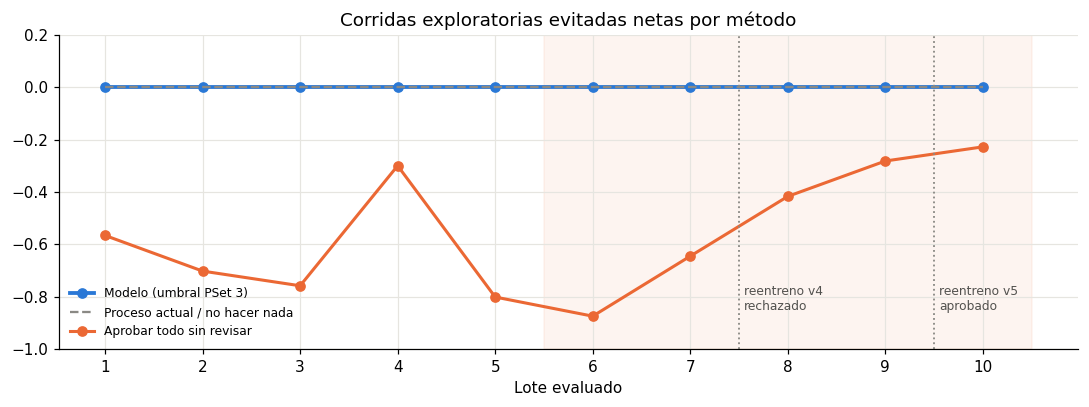

Total en 10 lotes: modelo 0.00 · proceso actual 0 · aprobar todo -5.57 corridas netas por método.
Orden de elución correcto en pares con Δ predicha >= 2 min: 86%–100% por lote.


In [12]:
neg = tabla(metricas=["corridas_evitadas_netas", "neto_linea_base", "neto_aprobar_todo", "tasa_aprobacion",
                         "aprobaciones_fallidas", "tasa_metodos_separables", "orden_exactitud_2min"], eje="lote_evaluado")
version = mon[mon.metrica == "rmse"].set_index("lote_evaluado")["version_modelo"]
neg["version_que_predijo"] = version
neg["reentrenamiento_despues"] = neg.index.map(lambda l: next((f"semana {s}: v{int(v)} {d}" for s, v, d in
                                   zip(reent.lote, reent.version_challenger, reent.decision_humana) if s == l + 1), ""))
display(neg.round(3))

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(neg.index, neg.corridas_evitadas_netas, color=AZUL, marker="o", lw=2.5, label="Modelo (umbral PSet 3)")
ax.plot(neg.index, neg.neto_linea_base, color=GRIS, ls="--", lw=1.5, label="Proceso actual / no hacer nada")
ax.plot(neg.index, neg.neto_aprobar_todo, color=NARANJA, marker="o", lw=2, label="Aprobar todo sin revisar")
for s, v, d in zip(reent.lote, reent.version_challenger, reent.decision_humana):
    ax.axvline(s - 1 + 0.5, color=GRIS, ls=":", lw=1.2)
    ax.text(s - 1 + 0.55, -0.85, f"reentreno v{v}\n{d}", fontsize=8, color="#52514e")
ax.axvspan(DERIVA_DESDE_LOTE - 0.5, 10.5, color=NARANJA, alpha=0.07)
ax.set(title="Corridas exploratorias evitadas netas por método", xlabel="Lote evaluado", xticks=range(1, 11), ylim=(-1, 0.2))
ax.legend(frameon=False, fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()
print(f"Total en 10 lotes: modelo {neg.corridas_evitadas_netas.sum():.2f} · proceso actual 0 · aprobar todo {neg.neto_aprobar_todo.sum():.2f} corridas netas por método.")
print(f"Orden de elución correcto en pares con Δ predicha >= 2 min: {neg.orden_exactitud_2min.min():.0%}–{neg.orden_exactitud_2min.max():.0%} por lote.")

**¿Valió la pena actuar según la predicción?** **Todavía no, en la métrica de negocio.** El modelo empata con el proceso actual (0 corridas evitadas netas en los 10 lotes) porque nunca aprueba un método. Su intervalo de error por par, calibrado al 95 % (unos ±8 min), es mucho más ancho que la separación que necesita el analista (0,5 min). La alternativa de confiar a ciegas (aprobar todo) habría costado entre 0,23 y 0,87 corridas **extra** por método, porque entre el 6 % y el 39 % de los métodos reales son separables. Que el modelo se abstenga es el comportamiento correcto con la incertidumbre que tiene: **no ahorra, pero tampoco hace daño**.

**Efecto de los reentrenamientos.** No movieron la métrica de negocio, porque ningún challenger estrecha el intervalo lo suficiente para aprobar. En error técnico, el v5 corrige el lote 09 (RMSE 3,43 → 2,86), y el v4 rechazado habría corregido más (sección 4.1). Eso sería lo primero que aprovecharía un umbral más fino.

**Lo que sí aporta hoy:** en pares con diferencia predicha de 2 min o más, el modelo acierta el **orden de elución** en el 86–99 % de los casos por lote. El analista puede usarlo para planificar la corrida exploratoria, aunque no para saltársela.

**Qué haría falta para generar ahorro:** un RMSE de unos 0,5 min en métodos conocidos. Por ejemplo, ajustando el modelo con 1 o 2 estándares medidos en el propio método del laboratorio (calibración por método) en lugar de predecir desde cero. El techo de ahorro medido es del 19 % de las corridas exploratorias.